# Cell type analysis

The purpose of this analysis is to assign a cell type information to each of the cortical layers in the resolutions of interest. This cell type information has been generated using the tool Cell2Location. All cell2location scores have been normalised by the total unique molecular identifiers in that spot (i.e. total RNA strands). 

Outputted information: 
- Median cell2location score per individual (rows) and layer (columns)
- Standard deviation of cell2 location score per individual (rows) and layer (columns)
- Top 3 cell types assigned to each spot (hot 1 encoded). Cell2Location gives a probability that a cell type is in a given spot, and on average a spot has 3 cells - like this we only get cell type information that we are more confident about. 

In [1]:
###--------------------------------------------LOAD LIBRARIES
import scanpy as sc
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import copy

In [2]:
adata =  sc.read("../../../DLPFC_data/DLPFC_Visium/combined_dataframes/nonIF_c2l_anndata_combined_30samples.h5ad")



# 1.0 - 4 Cortical Layers

In [3]:
# Prepare data

subset = adata[adata.obs['bayesSpace_harmony_7'].isin([1,2,3,4,5,6])]   # Excluding WM and meningeal layers

subset.obs['bayesSpace_harmony_7'] = subset.obs['bayesSpace_harmony_7'].replace({   # Renaming to match order of MRI (L1, closer to WM, L4 closer to meninges)
                                                     1 : 'L1',
                                                     2 : 'L4', 
                                                     3 : 'L3', 
                                                     4 : 'L2', 
                                                     5 : 'WM',
                                                     6 : 'L1'})

subset.obs['sample_id'] = subset.obs['sample_id'].astype(str)

df_deconvo = subset.obs[np.isnan(subset.obs['Oligo'])==False]

deconvo = ['Astro',
 'EndoMural',
 'Excit_L2_3',
 'Excit_L3',
 'Excit_L3_4_5',
 'Excit_L4',
 'Excit_L5',
 'Excit_L5_6',
 'Excit_L6',
 'Inhib',
 'Micro',
 'OPC',
 'Oligo']

/tmp/slurm_12196649/ipykernel_3529241/948312439.py:5: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  subset.obs['bayesSpace_harmony_7'] = subset.obs['bayesSpace_harmony_7'].replace({   # Renaming to match order of MRI (L1, closer to WM, L4 closer to meninges)


norm_Astro


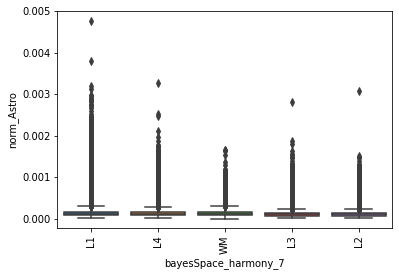

norm_EndoMural


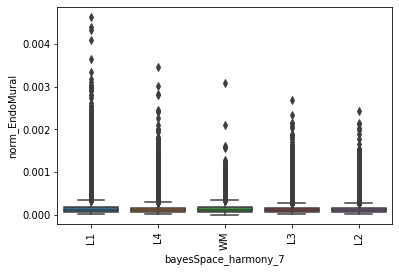

norm_Excit_L2_3


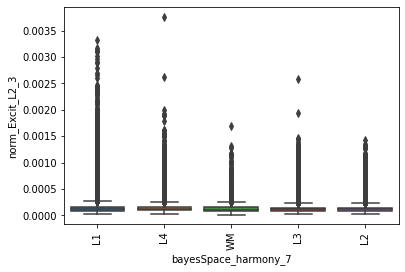

norm_Excit_L3


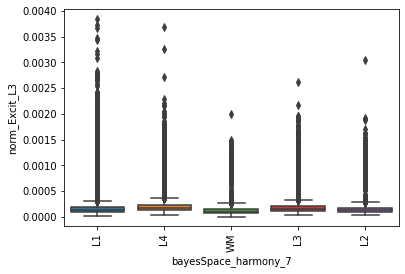

norm_Excit_L3_4_5


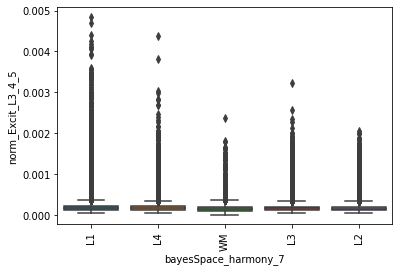

norm_Excit_L4


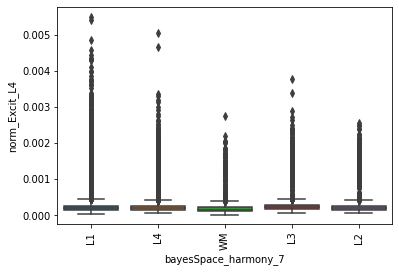

norm_Excit_L5


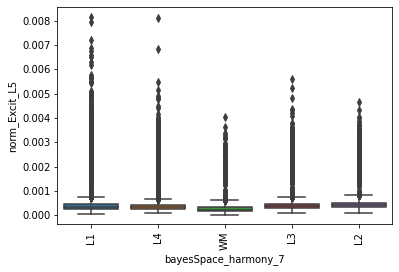

norm_Excit_L5_6


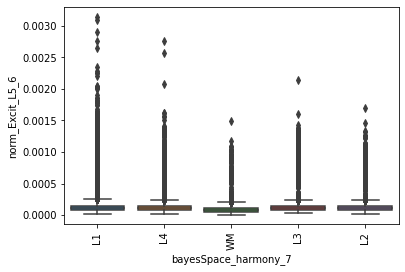

norm_Excit_L6


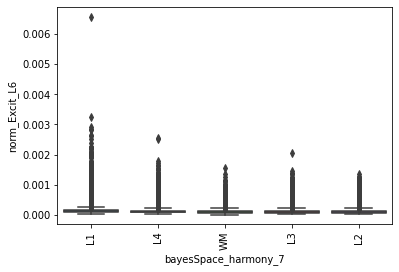

norm_Inhib


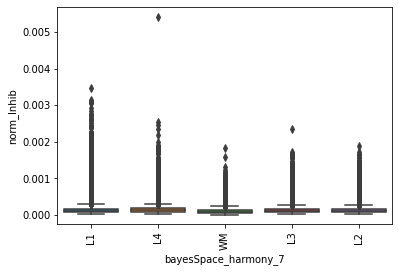

norm_Micro


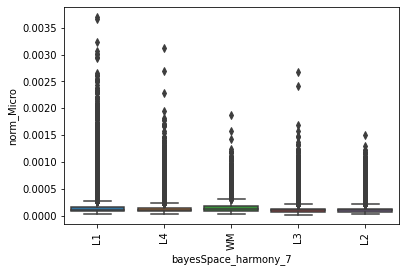

norm_OPC


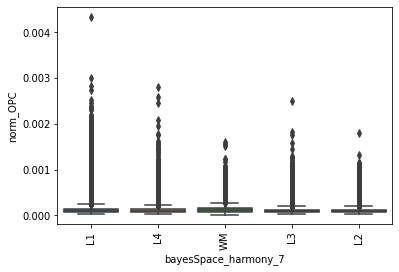

norm_Oligo


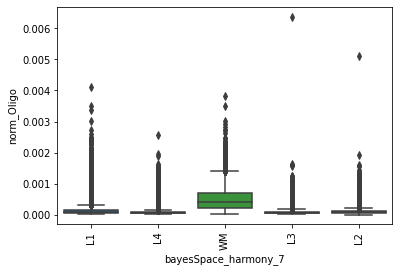

In [4]:
for n in range(0,len(deconvo)):
    col_name = 'norm_'+deconvo[n]
    print(col_name)
    df_deconvo.loc[:, col_name] = df_deconvo[deconvo[n]]/df_deconvo['sum_umi']
    median = df_deconvo.groupby(['sample_id', 'bayesSpace_harmony_7']).median()[col_name].reset_index()
    median.pivot(index='sample_id', columns='bayesSpace_harmony_7', values=col_name).to_csv('../../processed_data/01b-4layers_withendo/01-Cell_type_scores/median_'+col_name+'_4layers.csv')
        
    SD = df_deconvo.groupby(['sample_id', 'bayesSpace_harmony_7']).std()[col_name].reset_index()
    SD.pivot(index='sample_id', columns='bayesSpace_harmony_7', values=col_name).to_csv('../../processed_data/01b-4layers_withendo/01-Cell_type_scores/SD_'+col_name+'_4layers.csv')

    #Plot normalised score per cell type across cortical layers
    sns.boxplot(x=df_deconvo['bayesSpace_harmony_7'], y=df_deconvo[col_name])
    plt.xticks(rotation=90)
    plt.savefig('../../plots/01b-4layers_withendo/01-Cell_type_scores/score_per_layer_%s.png' % deconvo[n])
    plt.show()    
